# NAQsim：小型线路的逐 pass 编译与执行

本 demo 使用 **3 个逻辑比特**，逐个调用 NAQsim 原始模块，展示每个 pass 的输入、输出和可视化。
它包含显式 reset、H、CX、S、T 与终端测量，能够观察旋转插入、资源态传送、寄存器重命名、映射、移动与 ESM。

配置经确认：`NAIVE_SKIP` + `AGGREGATE`，码距 `d=3`，上游反射旋转硬件基线，默认 SA 映射（内部种子 0）。
内核为 conda 环境 **py311**；该环境已按要求升级到 **Python 3.13**，环境名不表示 Python 3.11。

| 边界 | 实际实现 | 输入 → 输出 |
| --- | --- | --- |
| Pass 1 | `tsc_inst_translator` | Qiskit 线路 → 指令依赖 DAG |
| Pass 2 | `plane_initializer` | 比特数、平面类型 → M/Y/N 字符网格 |
| Pass 3 | `tsc_inst_scheduler` | DAG、网格、策略 → 逻辑指令层与资源请求层 |
| Pass 4 | `sa_mapper` | 指令层、网格 → 初始逻辑比特映射 |
| Pass 5 | `tsc_uop_scheduler_comptime` | 编译结果、硬件配置 → µop 时间区间与层末状态 |

上游将前四步称为 `compilation_stage`，第五步称为 `execution_stage`。本 notebook 展开这些模块边界；
其图形是逻辑 patch 和架构资源的表示。说明用中文，图内标签用英文，以避免跨平台字体缺字。

从上到下运行全部单元格。详细使用方法见同目录 [README.md](README.md)。


## 0. 内核、源码路径和配置

这里只加载 demo 所需的本地源码，不安装整个上游包。启动目录可以是父项目根目录、NAQsim 根目录或 `notebooks/`。
`experiment_config` 按相对路径读取硬件 JSON，因此仅在构造配置时临时切换目录，随后恢复 notebook 的工作目录。


In [1]:
from pathlib import Path
from contextlib import contextmanager
from copy import deepcopy
from importlib.metadata import version
from time import perf_counter
from hashlib import sha256
import os
import sys
import json
import subprocess

assert Path(sys.prefix).name.lower() == "py311", f"请选择 py311 内核；当前为 {sys.executable}"
assert sys.version_info >= (3, 13), f"上游要求 Python ≥3.13，当前为 {sys.version}"

def find_naqsim_root():
    for parent in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        for candidate in (parent, parent / "external" / "naqsim"):
            if (candidate / "src" / "tsc_naa_sim" / "tsc_inst_translator.py").is_file():
                return candidate
    raise FileNotFoundError("找不到 NAQsim；请在项目根目录或 external/naqsim/notebooks 启动。")

NAQSIM_ROOT = find_naqsim_root()
TSC_DIR = NAQSIM_ROOT / "src" / "tsc_naa_sim"
NOTEBOOK_DIR = NAQSIM_ROOT / "notebooks"
sys.path.insert(0, str(TSC_DIR))
sys.path.insert(0, str(NOTEBOOK_DIR))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rustworkx as rx
from IPython.display import display, Markdown
from qiskit import QuantumCircuit
from config import experiment_config
from macro import RotTransOpt, RotSchedOpt
from tsc_instructions import InstType, UopType
from tsc_inst_translator import tsc_inst_translator
from plane_initializer import plane_initializer
from tsc_inst_scheduler import tsc_inst_scheduler
from tsc_qubit_mapper_jit import sa_mapper, NUMBA_AVAILABLE
from tsc_uop_scheduler_comptime import tsc_uop_scheduler_comptime
import demo_visualization as viz

%matplotlib inline
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

@contextmanager
def working_directory(path):
    previous = Path.cwd()
    try:
        os.chdir(path)
        yield
    finally:
        os.chdir(previous)

with working_directory(TSC_DIR):
    cfg = experiment_config()
cfg.code_dist = 3
cfg.rot_trans_opt = RotTransOpt.NAIVE_SKIP
cfg.rot_sched_opt = RotSchedOpt.AGGREGATE

timings = {}

def show_figure(fig):
    display(fig)
    plt.close(fig)

print(f"Interpreter: {sys.executable}")
print(f"Python: {sys.version.split()[0]}")
print(f"Source: {TSC_DIR}")
display(pd.DataFrame([{"package": name, "version": version(name)} for name in
                      ["qiskit", "numpy", "pandas", "scipy", "rustworkx", "matplotlib", "ipykernel"]]))


Interpreter: C:\Users\lys\.conda\envs\py311\python.exe
Python: 3.13.14
Source: D:\work\naqc\FT compiler\external\naqsim\src\tsc_naa_sim


,package,version
0,qiskit,1.2.4
1,numpy,2.1.2
2,pandas,2.2.3
3,scipy,1.14.1
4,rustworkx,0.18.0
5,matplotlib,3.9.2
6,ipykernel,7.3.0


In [2]:
config_fields = ["code_dist", "rounds", "plane_type", "rot_trans_opt", "rot_sched_opt",
                 "inst_sched_opt", "s_trans_opt", "rot_type", "refl_type_h", "refl_type_d",
                 "move_type", "cx_type", "meas_type", "aod_sched_opt", "mov_twostep_opt",
                 "lattice_bound", "cell_size", "rot_plane_opt", "num_rot_cell",
                 "is_aod_infinite", "skip_uop_grouping", "skip_h",
                 "num_aodh_max", "num_aodd_max", "num_aodr_max"]
config_df = pd.DataFrame([{"parameter": name, "value": getattr(getattr(cfg, name), "name", getattr(cfg, name))}
                         for name in config_fields])
display(config_df)
display(pd.json_normalize(cfg.hw_cfg).T.rename(columns={0: "hardware_value"}))


,parameter,value
0,code_dist,3
1,rounds,1
2,plane_type,ALLQ
3,rot_trans_opt,NAIVE_SKIP
4,rot_sched_opt,AGGREGATE
5,inst_sched_opt,ASAP
6,s_trans_opt,GATE_TEL
7,rot_type,REFL
8,refl_type_h,STATIC_SE
9,refl_type_d,STATIC_SE


,hardware_value
qubit.t2_idle_us,10000000.0
qubit.t2_star_us,10000000.0
qubit.t2_shutle_us,10000000.0
qubit.atom_spacing_um_zone,5
qubit.atom_spacing_um_select,10
operation.sq_gate.local.latency_us,1
operation.sq_gate.local.error_rate,0.0001
operation.sq_gate.global.latency_us,1
operation.sq_gate.global.error_rate,0.0001
operation.tq_gate.local.latency_us,1


## 输入线路

前三个 reset 是 NAQsim 的显式初始化指令。两个早期 H 可并行，后续 CX 连接三条线；S/T 触发 Y/M 资源请求。
H 会改变码块方向，翻译器根据后续 CX 的方向条件决定是否插入 ROT。
测量后的结果由架构模型记录依赖，本 demo 不抽样量子态或输出测量 bitstring。


,op_index,gate,qubits,clbits,params
0,0,reset,"(0,)",(),()
1,1,reset,"(1,)",(),()
2,2,reset,"(2,)",(),()
3,3,h,"(0,)",(),()
4,4,h,"(1,)",(),()
5,5,cx,"(0, 1)",(),()
6,6,t,"(1,)",(),()
7,7,cx,"(1, 2)",(),()
8,8,h,"(2,)",(),()
9,9,s,"(0,)",(),()


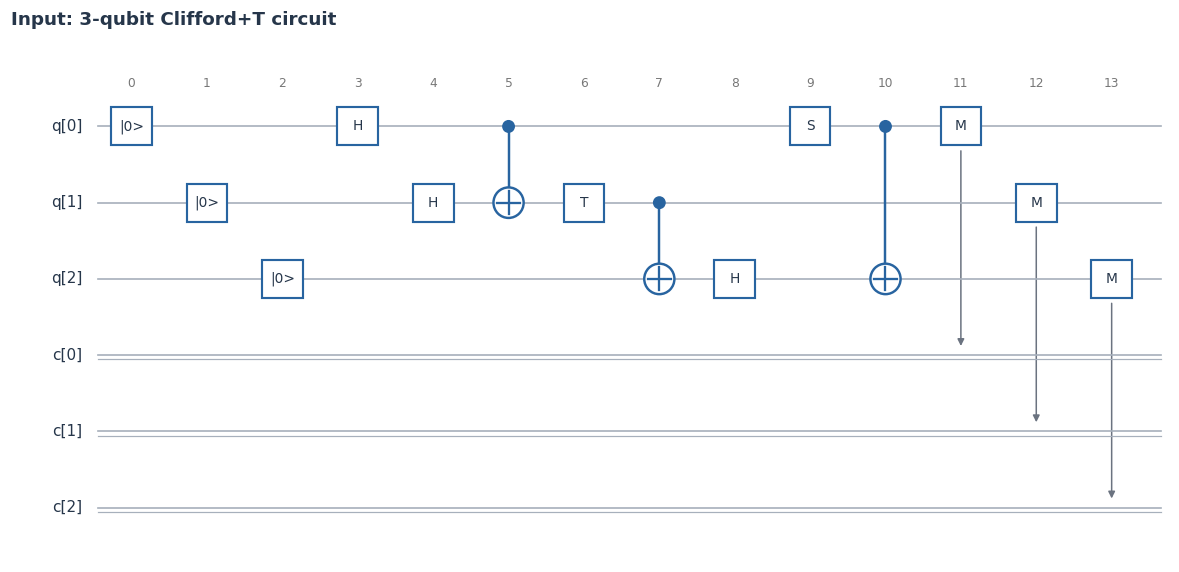

In [3]:
qc = QuantumCircuit(3, 3, name="naqsim_three_qubit_demo")
qc.reset(range(3))
qc.h(0)
qc.h(1)
qc.cx(0, 1)
qc.t(1)
qc.cx(1, 2)
qc.h(2)
qc.s(0)
qc.cx(0, 2)
qc.measure(range(3), range(3))

display(viz.circuit_table(qc))
show_figure(viz.draw_circuit(qc, title="Input: 3-qubit Clifford+T circuit"))


## Pass 1. 指令翻译与 ROT 插入

**输入：** `qc` 与 `rot_trans_opt/s_trans_opt`。**输出：** `translator.sc_dag`（rustworkx DAG）。
S/T 被展开为请求资源、CX、测量和条件修正；寄存器名称会随传送变化。依赖边保存量子/经典寄存器名称。
图中输入、输出和经典结果节点也是上游 DAG 的真实节点。


,parameter,value
3,rot_trans_opt,NAIVE_SKIP
6,s_trans_opt,GATE_TEL


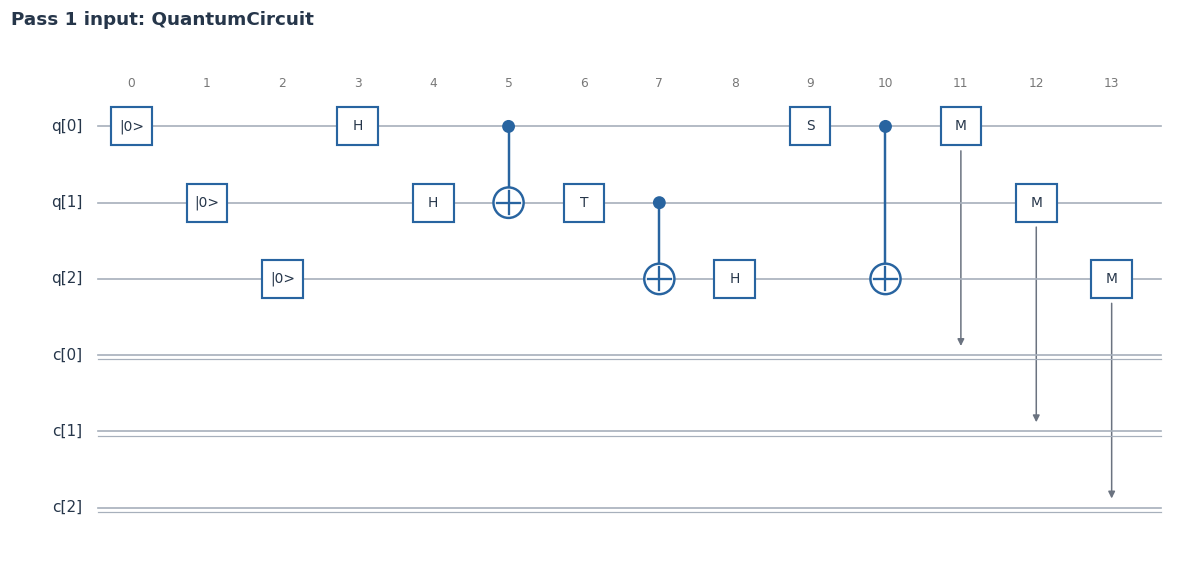

,node_id,node_type,name,qregs,condition_cregs,output_creg
0,0,INIT_Z,INIT_Z,"(Q0,)",(),
1,1,qreg_in,Q0,(),(),
2,2,TRANS_H,TRANS_H,"(Q0,)",(),
3,3,INIT_Z,INIT_Z,"(Q1,)",(),
4,4,qreg_in,Q1,(),(),
5,5,TRANS_H,TRANS_H,"(Q1,)",(),
6,6,TRANS_CX,TRANS_CX,"(Q0, Q1)",(),
7,7,REQ_Y,REQ_Y,"(Y0,)",(),
8,8,qreg_in,Y0,(),(),
9,9,TRANS_CX,TRANS_CX,"(Y0, Q0)",(),


,source,target,dependency
0,1,0,Q0
1,0,2,Q0
2,4,3,Q1
3,3,5,Q1
4,2,6,Q0
5,5,6,Q1
6,8,7,Y0
7,7,9,Y0
8,6,9,Q0
9,9,10,Q0


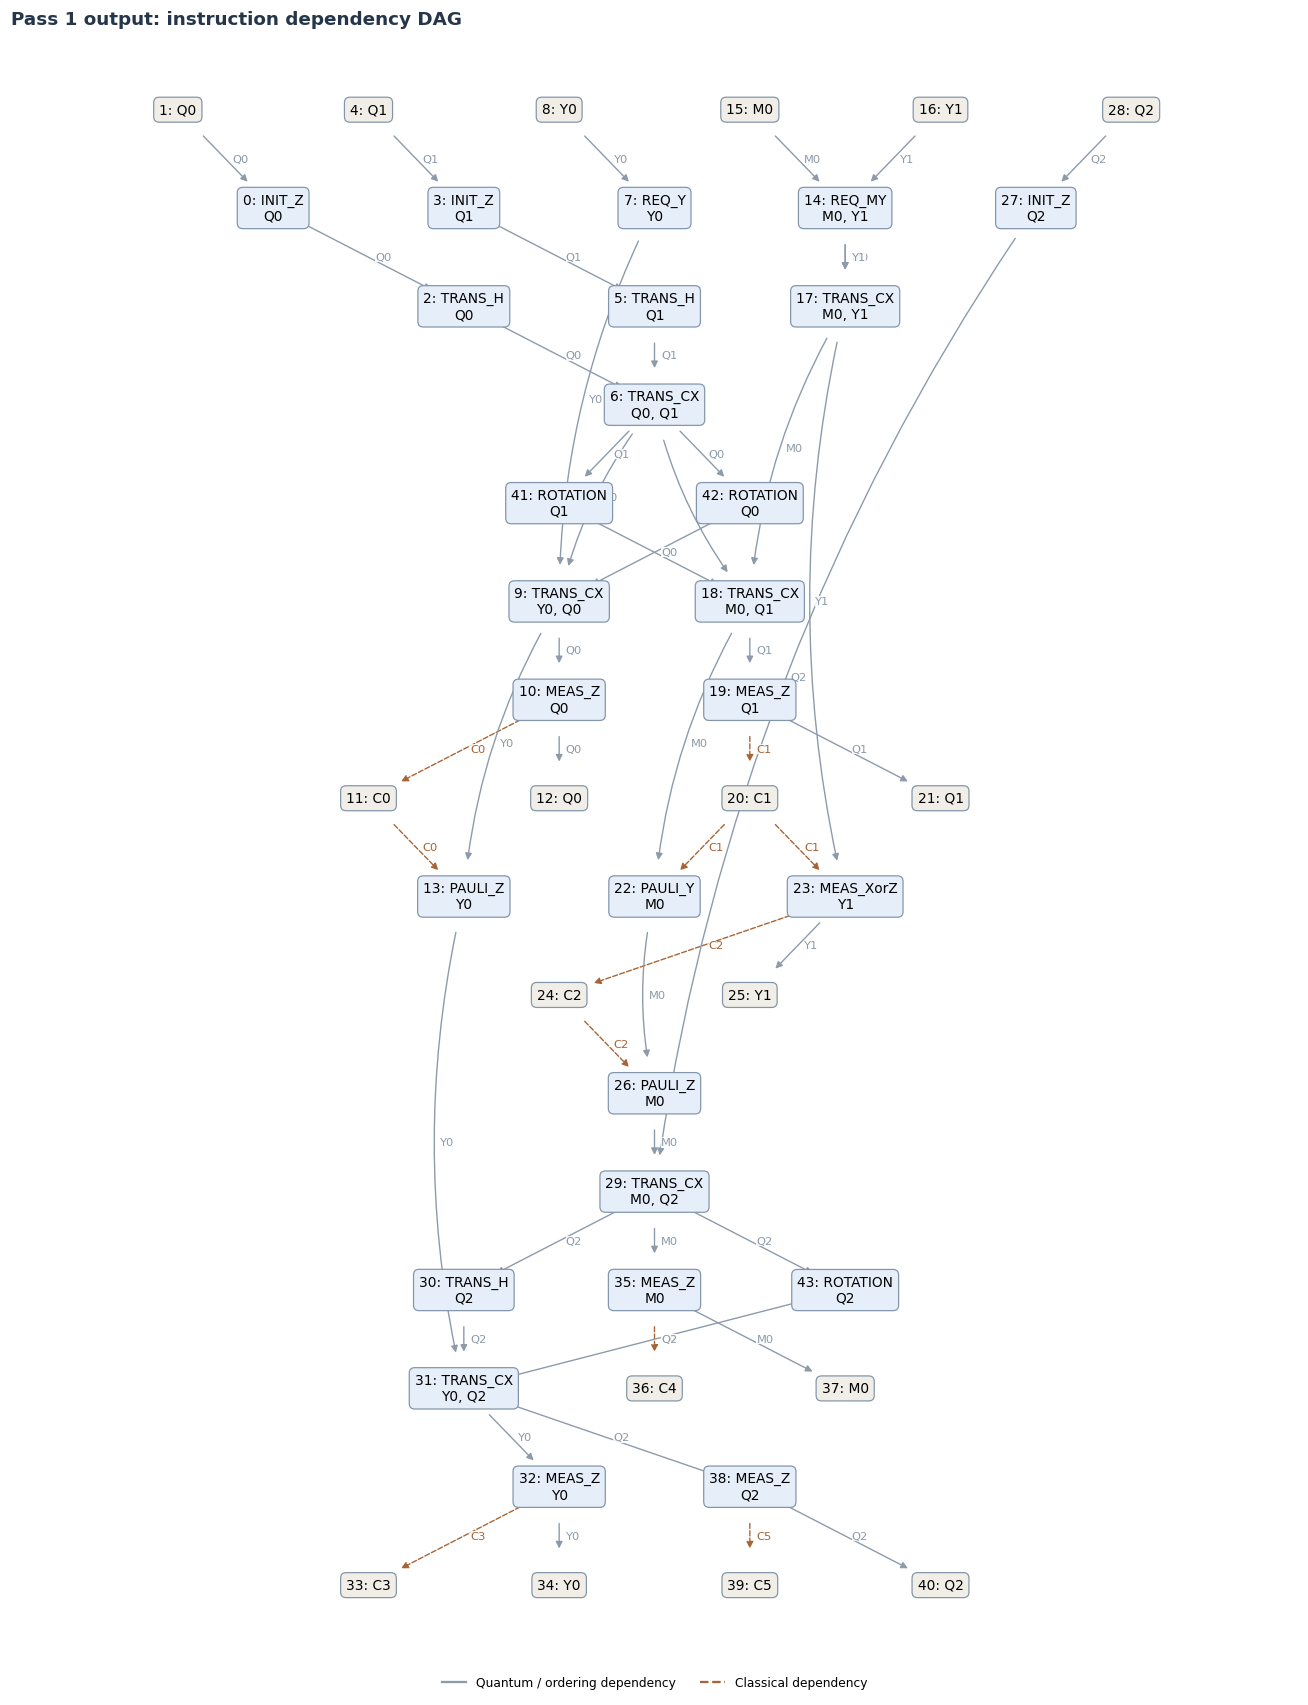

,original_qubit,current_register
0,Q0,Y0
1,Q1,M0
2,Q2,Q2


In [4]:
display(config_df[config_df.parameter.isin(["rot_trans_opt", "s_trans_opt"])])
show_figure(viz.draw_circuit(qc, title="Pass 1 input: QuantumCircuit"))
started = perf_counter()
translator = tsc_inst_translator(qc_qiskit_in=qc, rot_trans_opt=cfg.rot_trans_opt,
                                s_trans_opt=cfg.s_trans_opt)
translator.run()
inst_dag = deepcopy(translator.sc_dag)
timings["1 translator"] = perf_counter() - started
dag_nodes, dag_edges = viz.dag_tables(inst_dag)
display(dag_nodes)
display(dag_edges)
show_figure(viz.draw_dag(inst_dag, title="Pass 1 output: instruction dependency DAG"))
display(pd.DataFrame([{"original_qubit": name, "current_register": current}
                      for name, current in translator.qubit_tracking.items()]))


## Pass 2. 平面初始化

**输入：** 原始逻辑比特数 `qc.num_qubits=3` 与 `PlaneType.ALLQ`。**输出：** `plane_char`。
首行 M 端口、第二行 Y 端口、其余 N 普通 patch。此 pass 根据架构尺寸建网格，不接收 Pass 1 的 DAG；
它是随后调度和映射共同使用的旁路输入。


,num_lq,plane_type
0,3,ALLQ


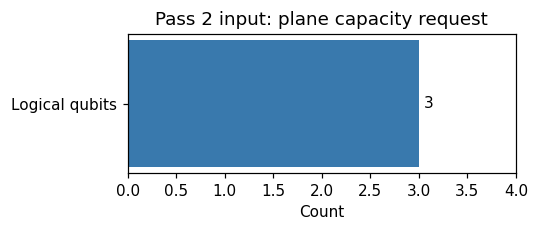

column,0,1,2
row,,,
0,M,M,M
1,Y,Y,Y
2,N,N,N


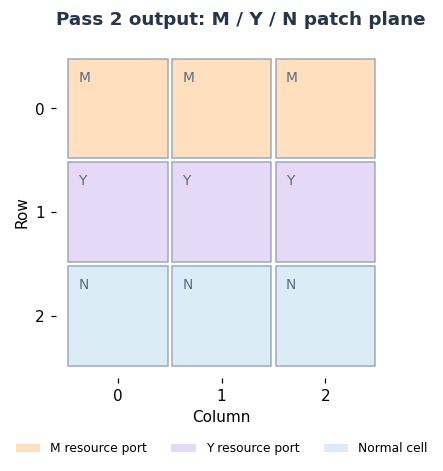

In [5]:
display(pd.DataFrame([{"num_lq": qc.num_qubits, "plane_type": cfg.plane_type.name}]))
fig, ax = plt.subplots(figsize=(5, 2.2))
ax.barh(["Logical qubits"], [qc.num_qubits], color="#3979ad")
ax.set(xlabel="Count", title="Pass 2 input: plane capacity request", xlim=(0, 4))
ax.text(qc.num_qubits + 0.05, 0, str(qc.num_qubits), va="center")
fig.tight_layout()
show_figure(fig)
started = perf_counter()
plane_init = plane_initializer(num_lq=qc.num_qubits, plane_type=cfg.plane_type)
plane_init.run()
plane_char = deepcopy(plane_init.plane_char)
timings["2 plane initializer"] = perf_counter() - started
display(pd.DataFrame(plane_char).rename_axis(index="row", columns="column"))
show_figure(viz.draw_plane(plane_char, title="Pass 2 output: M / Y / N patch plane"))


## Pass 3. 逻辑指令与旋转调度

**输入：** 指令 DAG、`plane_char` 和 ASAP/AGGREGATE 等选项。
**输出：** `inst_schedule_trace` 与 `req_schedule_trace`，二者以层号配对。
REQ 层专门记录资源请求；普通指令层包括 H/CX/ROT/测量/Pauli 等。表中的经典条件是静态依赖元数据。
同一逻辑层的事项会在执行阶段按子步骤展开，横排不表示所有事项在同一物理时刻执行。
调度器会破坏性消费 DAG，因此这里传入深拷贝，保留原始输入图。


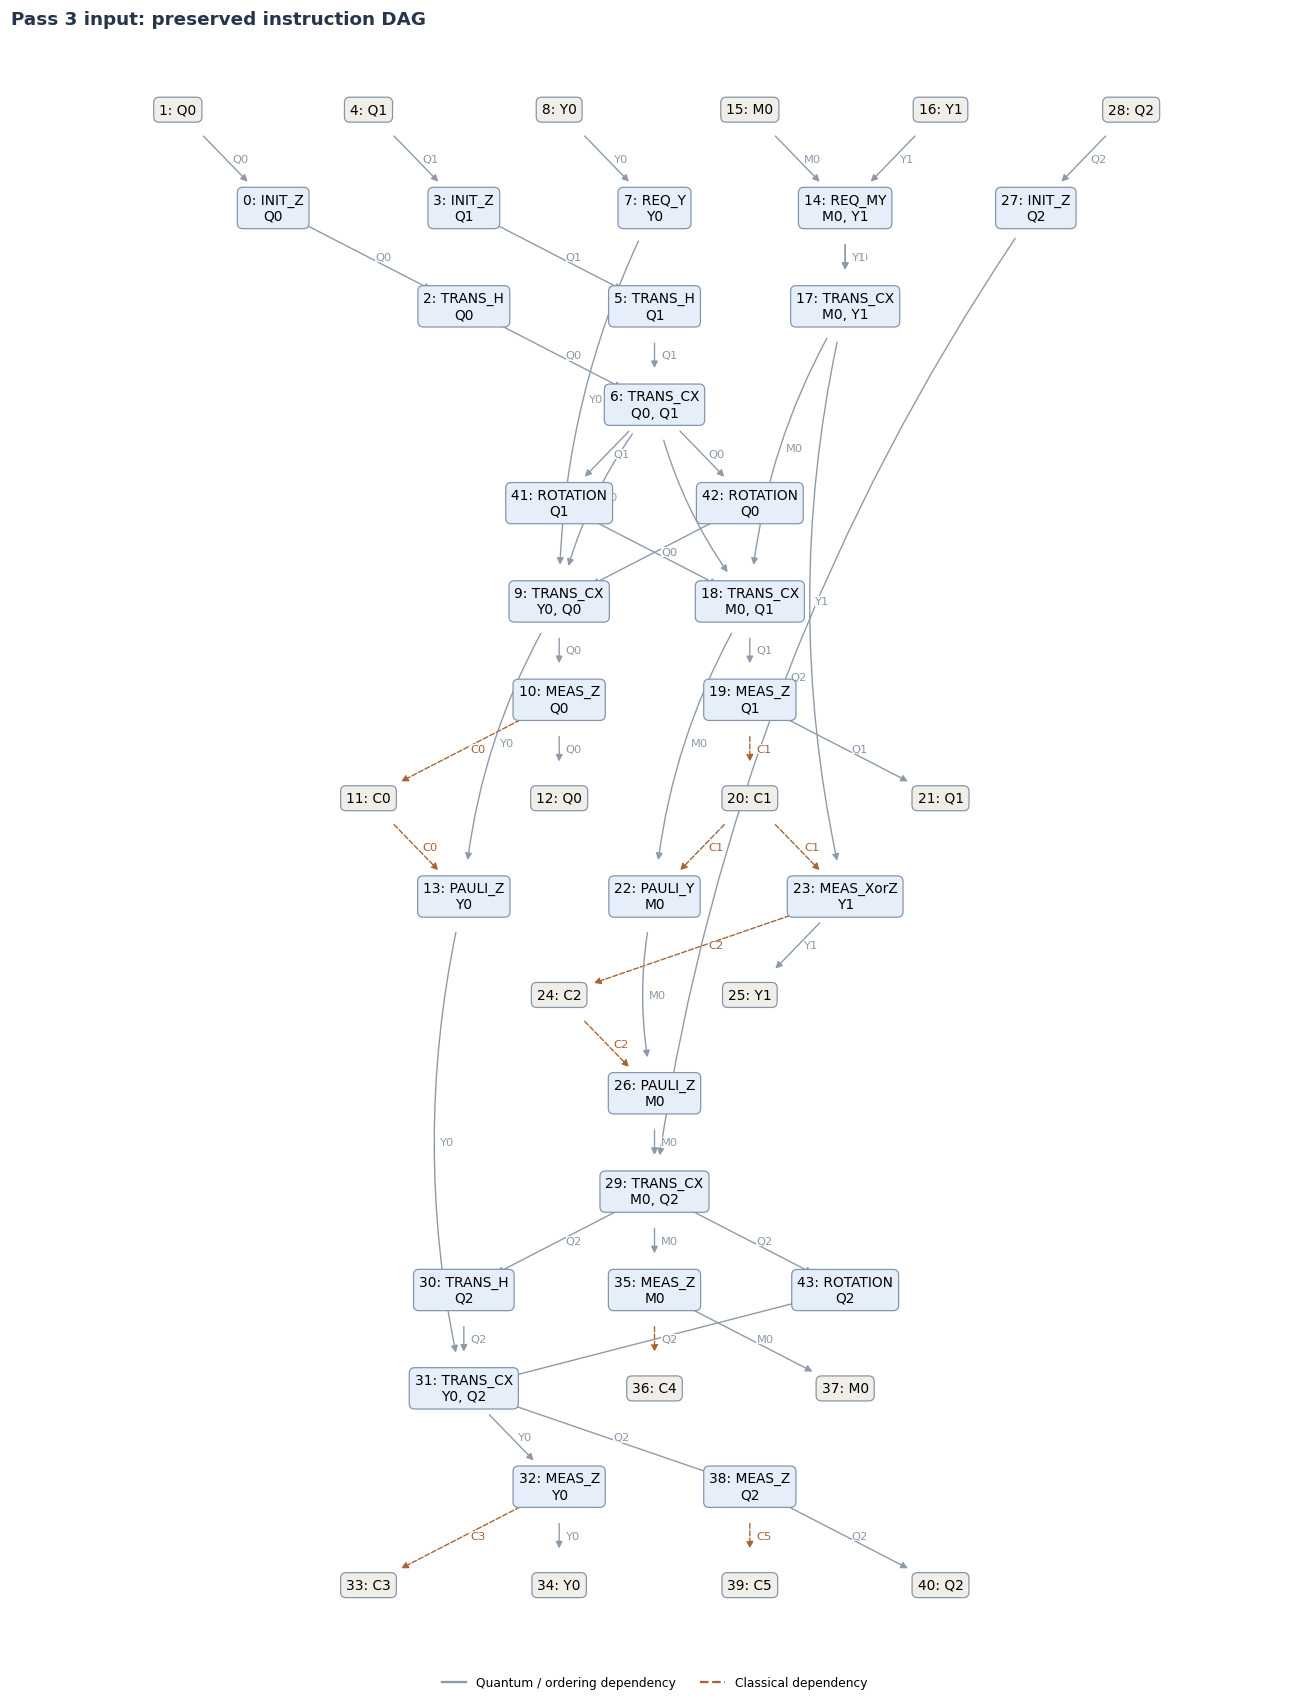

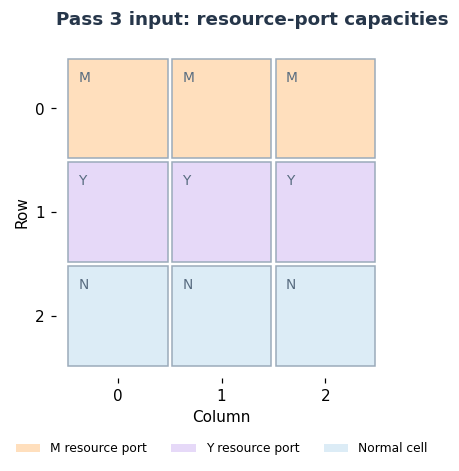

,parameter,value
4,rot_sched_opt,AGGREGATE
5,inst_sched_opt,ASAP
6,s_trans_opt,GATE_TEL
21,skip_h,False


,layer,kind,index_in_kind,inst_type,qregs,condition_cregs,output_creg,cx_type
0,0,request,0,REQ_MY,"(M0, Y1)",(),,
1,0,request,1,REQ_Y,"(Y0,)",(),,
2,0,instruction,0,TRANS_H,"(Q0,)",(),,
3,0,instruction,1,TRANS_H,"(Q1,)",(),,
4,0,instruction,2,TRANS_CX,"(M0, Y1)",(),,MY
5,1,instruction,0,TRANS_CX,"(Q0, Q1)",(),,QQ
6,2,instruction,0,TRANS_CX,"(Y0, Q0)",(),,YQ
7,2,instruction,1,TRANS_CX,"(M0, Q1)",(),,MQ
8,2,instruction,2,ROTATION,"(Q1,)",(),,
9,2,instruction,3,ROTATION,"(Q0,)",(),,


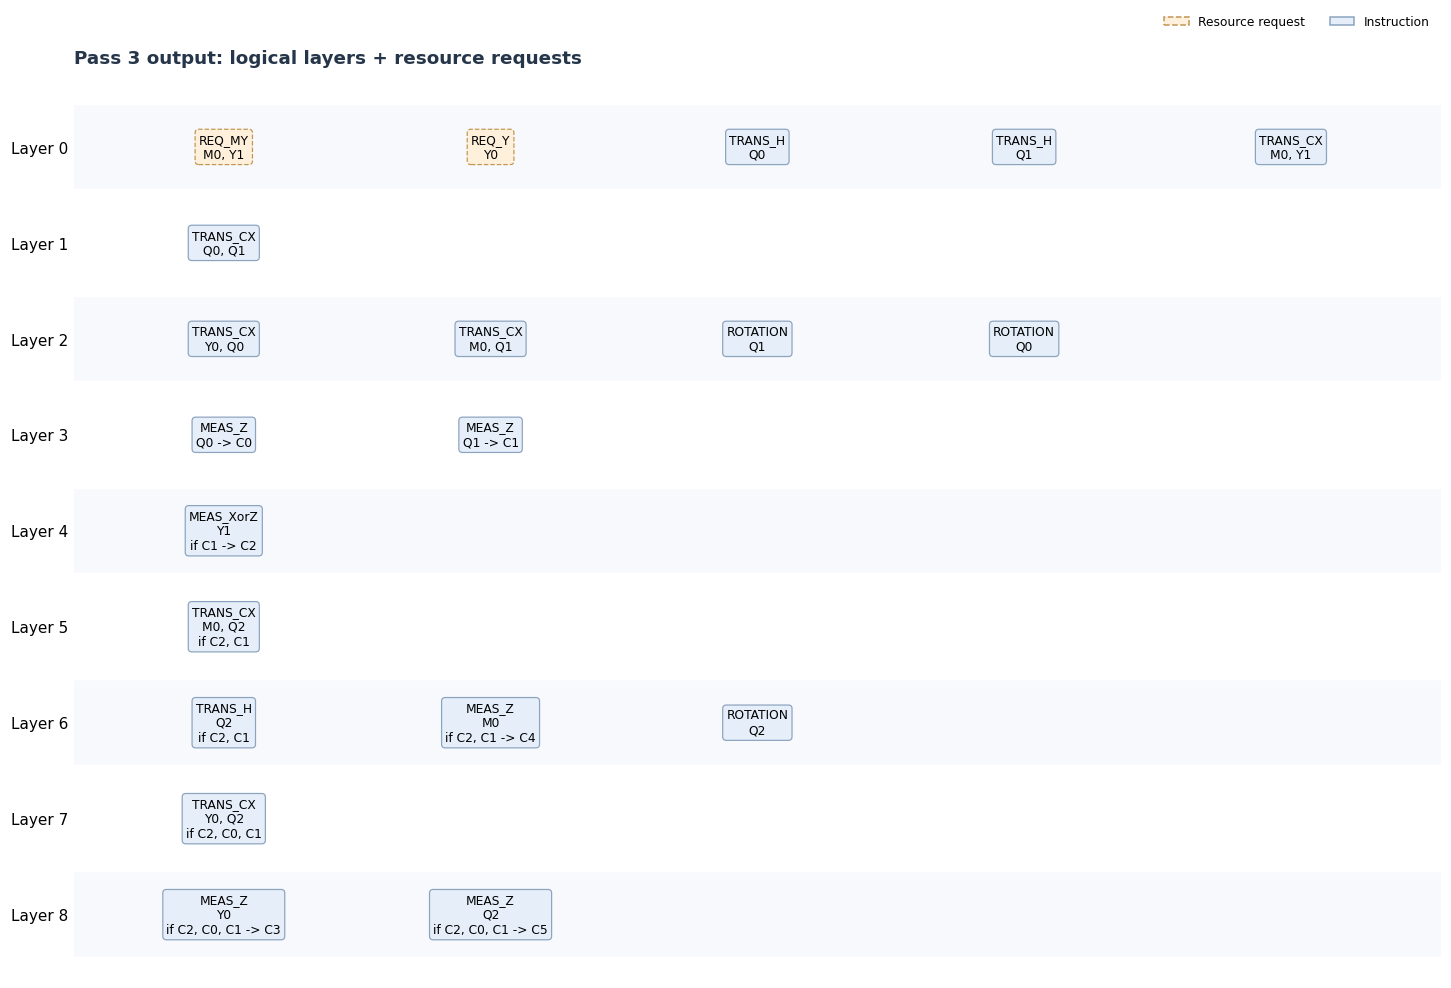

Logical layers: 9; input DAG retained: 44 nodes


In [6]:
show_figure(viz.draw_dag(inst_dag, title="Pass 3 input: preserved instruction DAG"))
show_figure(viz.draw_plane(plane_char, title="Pass 3 input: resource-port capacities"))
display(config_df[config_df.parameter.isin(["inst_sched_opt", "rot_sched_opt", "s_trans_opt", "skip_h"])])
started = perf_counter()
inst_scheduler = tsc_inst_scheduler(sc_dag_in=deepcopy(inst_dag), plane_char_in=deepcopy(plane_char),
                                   inst_sched_opt=cfg.inst_sched_opt, rot_sched_opt=cfg.rot_sched_opt,
                                   s_trans_opt=cfg.s_trans_opt, skip_h=cfg.skip_h,
                                   propagate_creg_names_cond=True)
inst_scheduler.run()
inst_schedule_trace = deepcopy(inst_scheduler.inst_schedule_trace)
req_schedule_trace = deepcopy(inst_scheduler.req_schedule_trace)
timings["3 instruction scheduler"] = perf_counter() - started
instruction_df = viz.instruction_table(inst_schedule_trace, req_schedule_trace)
display(instruction_df)
show_figure(viz.draw_instruction_layers(inst_schedule_trace, req_schedule_trace,
                                        title="Pass 3 output: logical layers + resource requests"))
print(f"Logical layers: {len(inst_schedule_trace)}; input DAG retained: {inst_dag.num_nodes()} nodes")


## Pass 4. SA 初始映射

**输入：** 指令层和网格。**输出：** `mapper.sa_mapping`（Q 名称 → `(row, column)`）。
SA 使用 CX 交互和资源端口访问的加权距离代理，不保证全局最优，也不直接优化完整执行时延。
使用上游默认参数与内部 `random.Random(0)`；可用 Numba 时执行原始 JIT 实现。
对照图左侧为退火初始扰动后的 `random_mapping`，属于映射器内部状态；右侧为最终 best mapping。


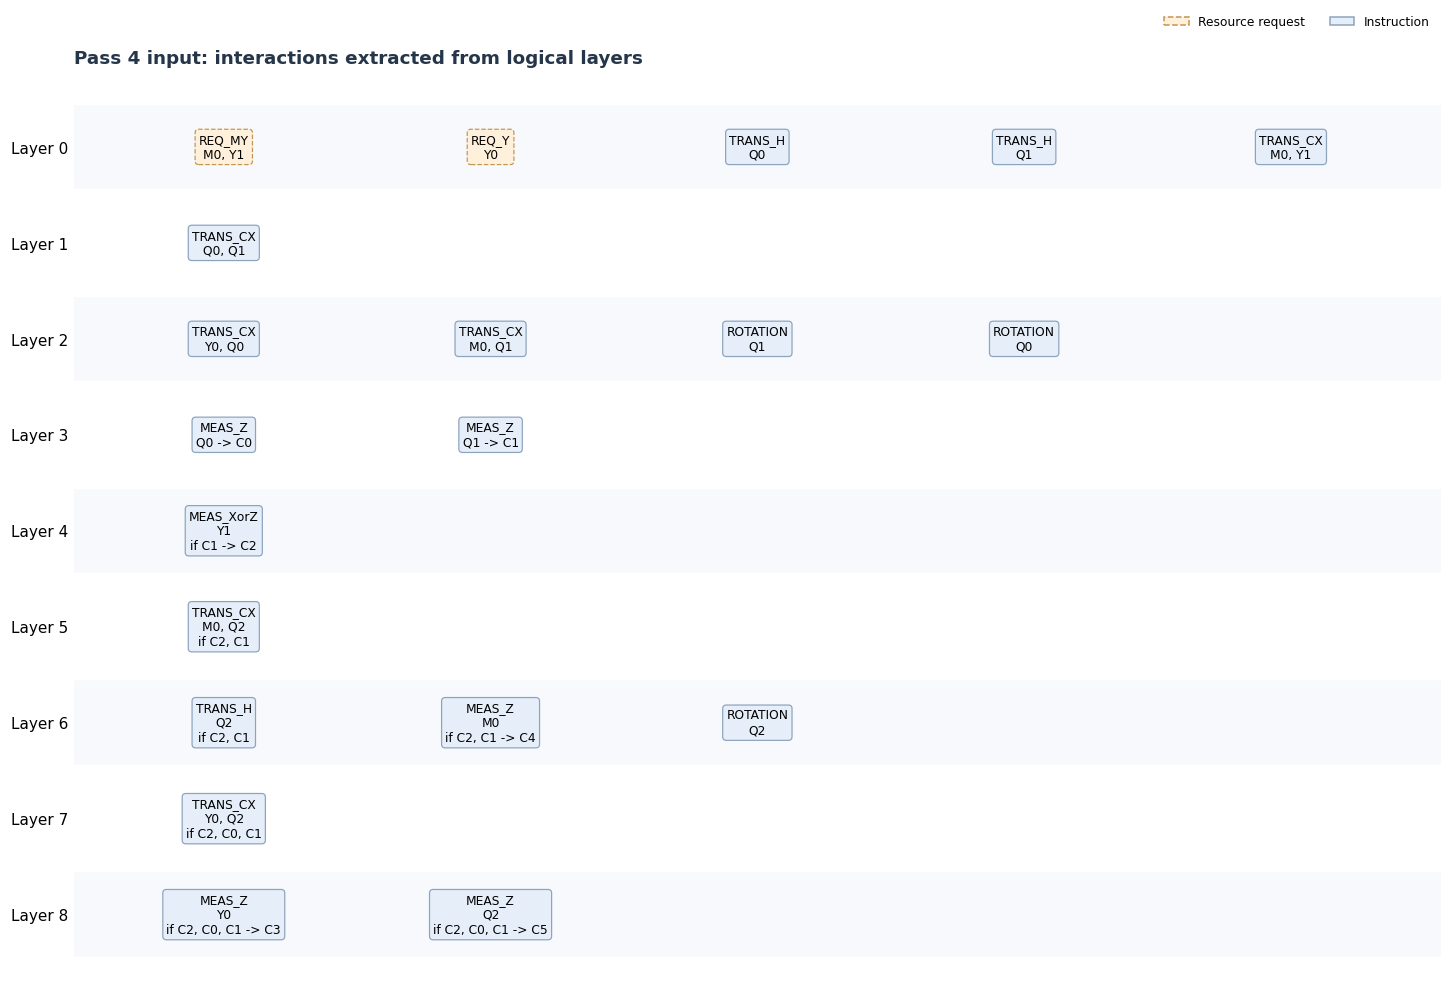

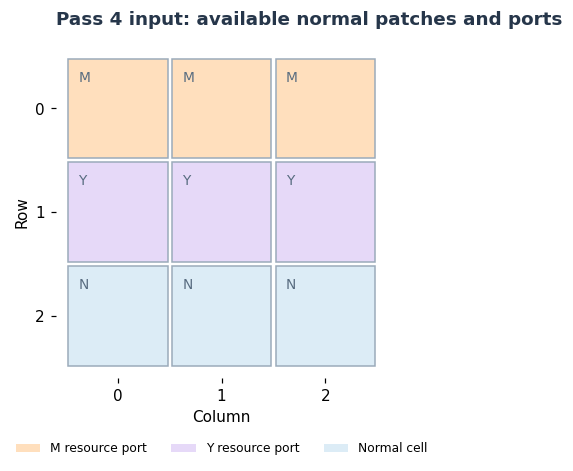

[INFO] JIT SA-based placement
[INFO] JIT SA-based placement: Iter 0, intial cost: 4.163889


[INFO] JIT SA-based placement: Iter0, cost: 4.163889


,register,row,column
0,Q0,2,0
1,Q1,2,1
2,Q2,2,2


,left,right,weight
0,Q0,Q1,0.9
1,Q0,Y0,0.8
2,Q0,Q2,0.6
3,Q1,Q2,0.7
4,M0,Q1,0.8


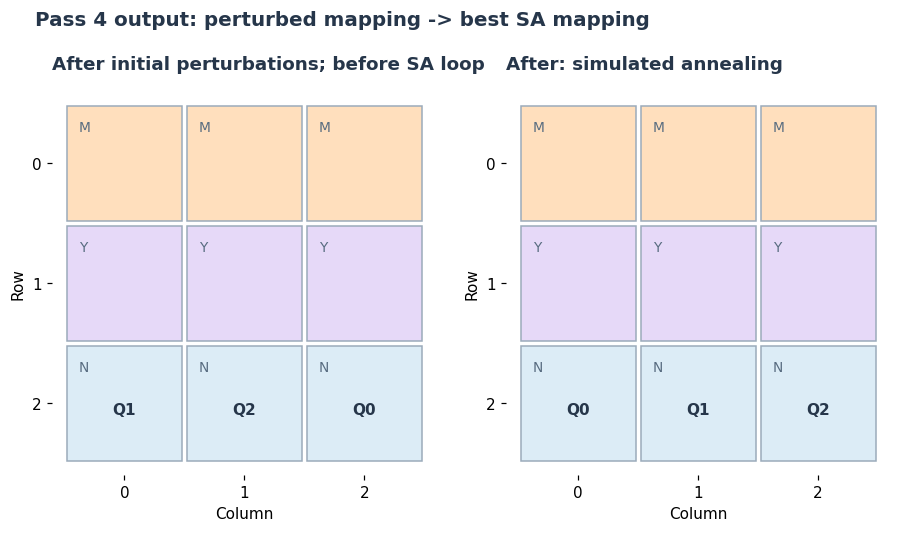

SA seed: 0 (upstream); Numba available: True; best proxy cost: 4.163889
Measured pass runtime: 0.695 s


In [7]:
show_figure(viz.draw_instruction_layers(inst_schedule_trace, req_schedule_trace,
                                        title="Pass 4 input: interactions extracted from logical layers"))
show_figure(viz.draw_plane(plane_char, title="Pass 4 input: available normal patches and ports"))
started = perf_counter()
mapper = sa_mapper(num_lq=qc.num_qubits, inst_schedule=deepcopy(inst_schedule_trace),
                   plane_char=deepcopy(plane_char))
mapper.run()
qmap_init = deepcopy(mapper.sa_mapping)
timings["4 SA mapper"] = perf_counter() - started
display(pd.DataFrame([{"register": name, "row": pos[0], "column": pos[1]}
                      for name, pos in qmap_init.items()]))
display(pd.DataFrame([{"left": left, "right": right, "weight": weight}
                      for left, neighbors in mapper.list_qubit_dict_gate.items()
                      for right, weight in neighbors.items() if left < right]))
show_figure(viz.draw_mapping_comparison(plane_char, mapper.random_mapping, qmap_init,
                                       title="Pass 4 output: perturbed mapping -> best SA mapping"))
print(f"SA seed: 0 (upstream); Numba available: {NUMBA_AVAILABLE}; best proxy cost: {mapper.best_cost:.6f}")
print(f"Measured pass runtime: {timings['4 SA mapper']:.3f} s")


## Pass 5. µop 生成与硬件资源调度

**输入：** `plane_char`、`qmap_init`、两类逻辑层 trace 与硬件配置。
**输出：** `uop_schedule_trace`、`plane_trace` 和 `qregs_trace`。
每层依次进行资源请求放置、前置单比特操作、AOD 搬运/旋转、双比特操作与 ESM。
路径冲突和旋转模型均开启；保留上游的充足 AOD、跳过分组假设。

每个 µop 区间记录为 `(uop, interval_type, (begin_us, end_us))`。同一 µop 可在多条激光资源线上占用区间。
**每层时间从 0 重新开始**：全程图通过累加各层 `max(end_us)` 拼接。资源线上的区间时长不能相加当成 makespan。


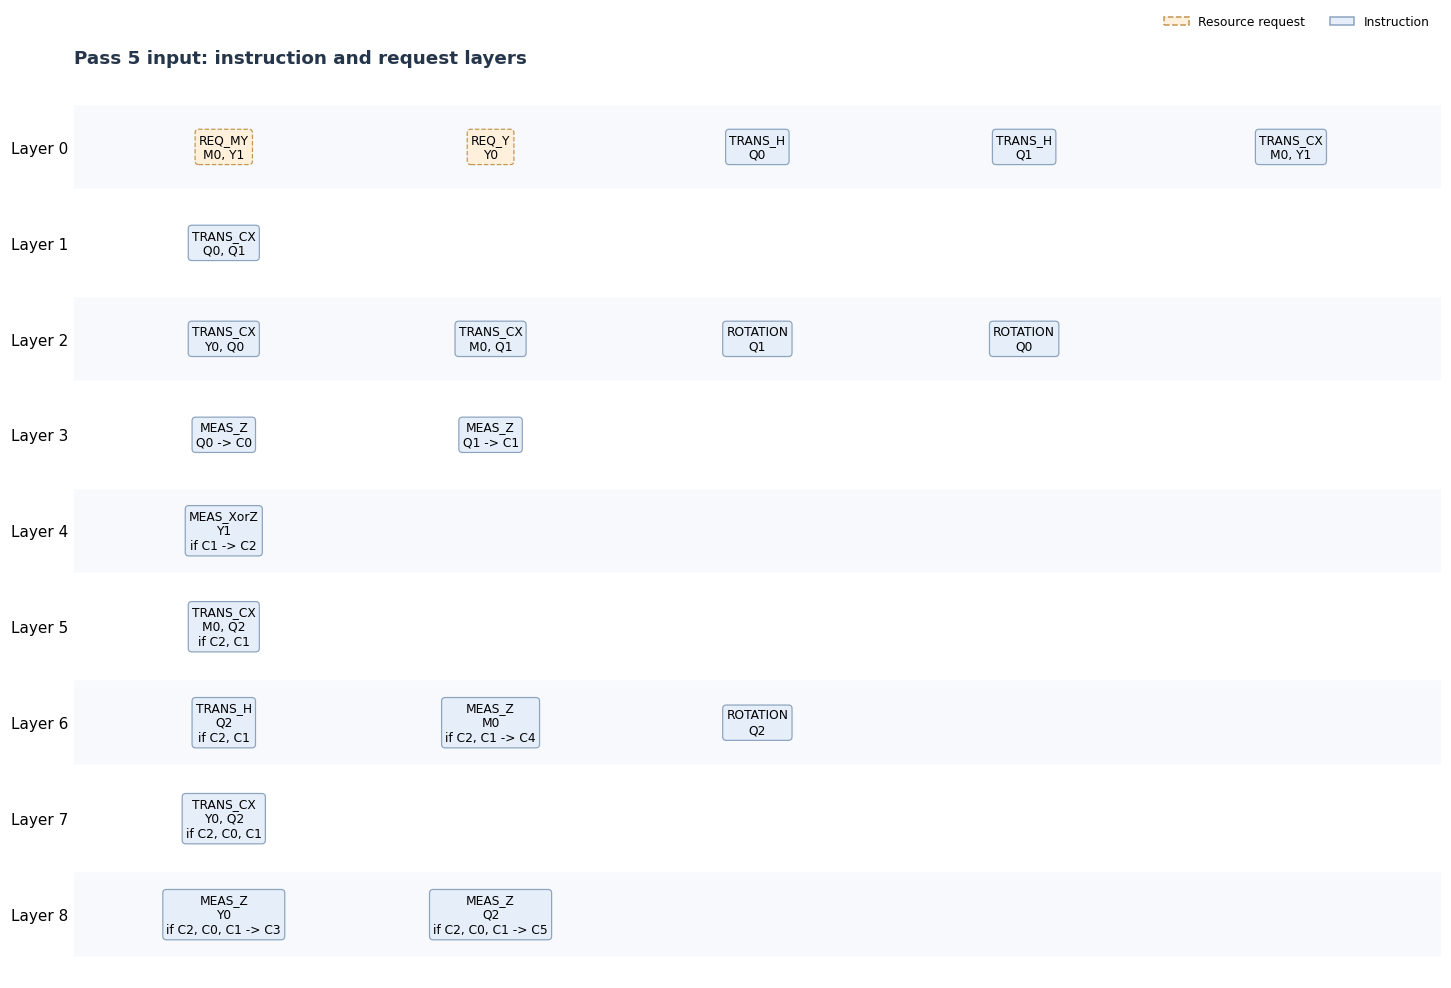

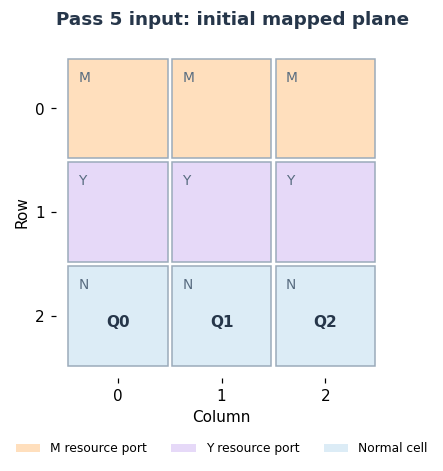

,parameter,value
0,code_dist,3
1,rounds,1
2,plane_type,ALLQ
3,rot_trans_opt,NAIVE_SKIP
4,rot_sched_opt,AGGREGATE
5,inst_sched_opt,ASAP
6,s_trans_opt,GATE_TEL
7,rot_type,REFL
8,refl_type_h,STATIC_SE
9,refl_type_d,STATIC_SE


,layer,duration_us,global_begin_us,global_end_us,interval_count,unique_uop_count,resource_count
0,0,428.09,0.00,428.09,16,4,4
1,1,427.09,428.09,855.18,15,3,4
2,2,907.05,855.18,1762.23,61,9,18
3,3,297.00,1762.23,2059.23,12,2,3
4,4,297.00,2059.23,2356.23,12,2,3
5,5,427.09,2356.23,2783.32,15,3,4
6,6,638.87,2783.32,3422.19,31,5,9
7,7,427.09,3422.19,3849.28,15,3,4
8,8,297.00,3849.28,4146.28,12,2,3


,layer,resource,interval_index,uop_id,uop_type,qregs,interval_type,begin_us,end_us,duration_us,layer_offset_us,global_begin_us,global_end_us
0,0,RMN_L,0,0,PATCH_H,"(Q0, Q1)",QOP,0.00,1.00,1.00,0.00,0.00,1.00
1,0,RMN_L,1,1,ESM,(),QOP,291.09,292.09,1.00,0.00,291.09,292.09
2,0,RMN_L,2,1,ESM,(),QOP,300.09,301.09,1.00,0.00,300.09,301.09
3,0,RMN_L,3,1,ESM,(),QOP,309.09,310.09,1.00,0.00,309.09,310.09
4,0,RMN_L,4,1,ESM,(),QOP,318.09,319.09,1.00,0.00,318.09,319.09
5,0,RMN_L,5,1,ESM,(),QOP,327.09,328.09,1.00,0.00,327.09,328.09
6,0,AODH_0,0,2,MOVE,"(M0,)",PICK,1.00,41.00,40.00,0.00,1.00,41.00
7,0,AODH_0,1,2,MOVE,"(M0,)",SHUTTLE,41.00,139.09,98.09,0.00,41.00,139.09
8,0,AODH_0,2,2,MOVE,"(M0,)",DROP,139.09,179.09,40.00,0.00,139.09,179.09
9,0,RYD_L,0,3,PATCH_CX,"(M0, Y1)",QOP,179.09,191.09,12.00,0.00,179.09,191.09


Complete interval table: uop_df (189 rows); complete register table: qregs_df


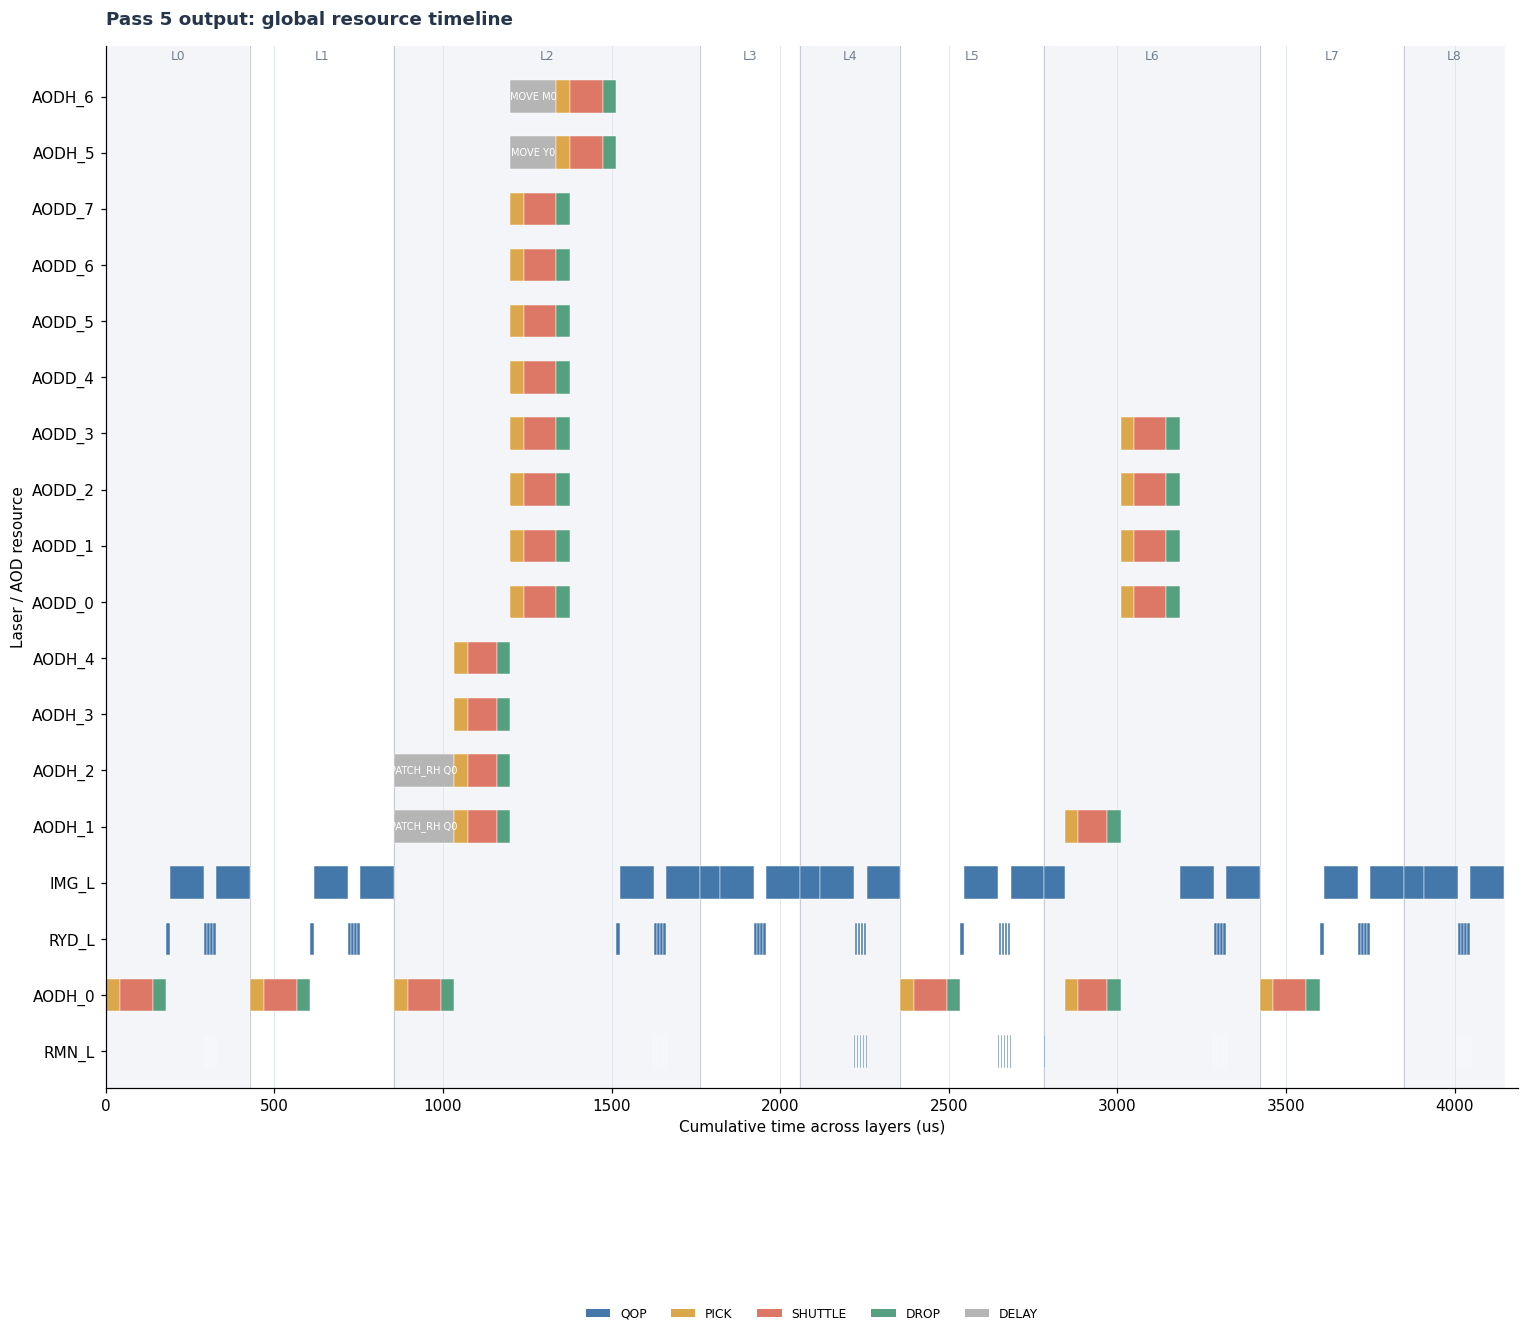

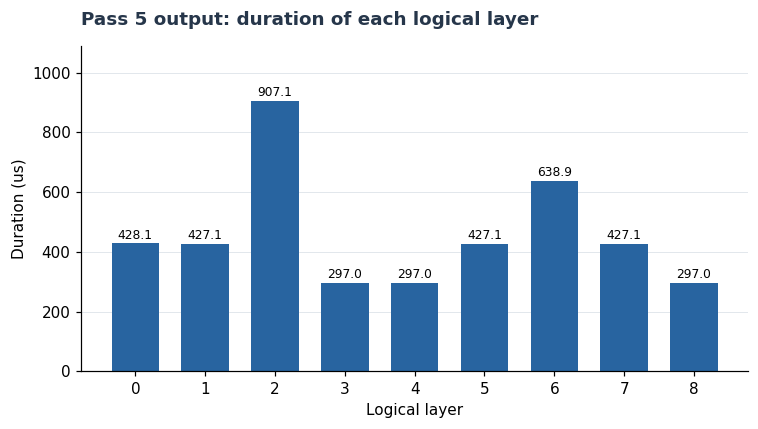

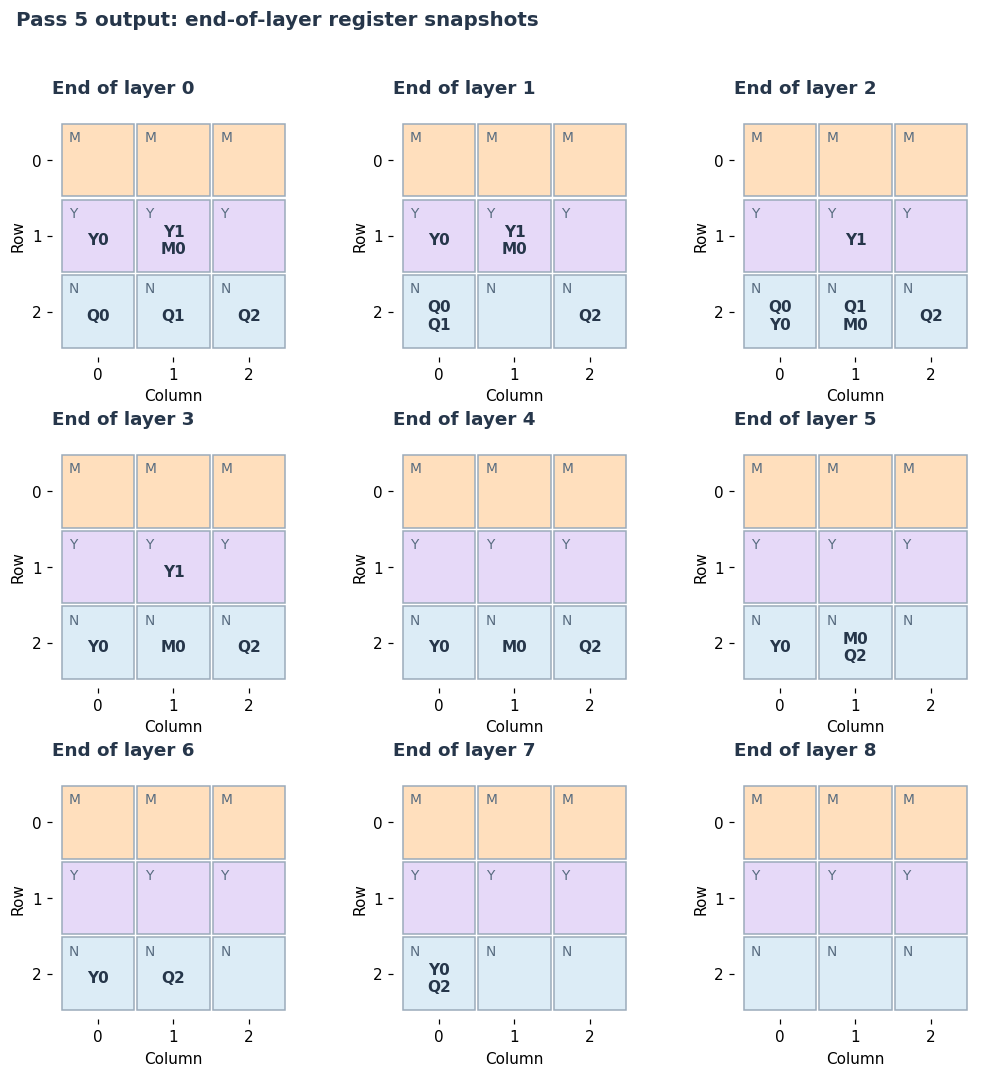

In [8]:
show_figure(viz.draw_instruction_layers(inst_schedule_trace, req_schedule_trace,
                                        title="Pass 5 input: instruction and request layers"))
show_figure(viz.draw_plane(plane_char, mapping=qmap_init, title="Pass 5 input: initial mapped plane"))
display(config_df)
started = perf_counter()
uop_scheduler = tsc_uop_scheduler_comptime(
    plane_char=deepcopy(plane_char), qmap_init=deepcopy(qmap_init),
    inst_schedule_trace=deepcopy(inst_schedule_trace), req_schedule_trace=deepcopy(req_schedule_trace),
    lattice_bound=cfg.lattice_bound, cell_size=cfg.cell_size, plane_type=cfg.plane_type,
    move_type=cfg.move_type, cx_type=cfg.cx_type, meas_type=cfg.meas_type, hw_cfg=deepcopy(cfg.hw_cfg),
    skip_uop_grouping=cfg.skip_uop_grouping, is_aod_infinite=cfg.is_aod_infinite,
    num_aodh_max=cfg.num_aodh_max, num_aodd_max=cfg.num_aodd_max, num_aodr_max=cfg.num_aodr_max,
    rot_type=cfg.rot_type, refl_type_h=cfg.refl_type_h, refl_type_d=cfg.refl_type_d,
    rot_plane_opt=cfg.rot_plane_opt, num_rot_cell=cfg.num_rot_cell,
    aod_sched_opt=cfg.aod_sched_opt, mov_twostep_opt=cfg.mov_twostep_opt,
    code_dist=cfg.code_dist, rounds=cfg.rounds, s_trans_opt=cfg.s_trans_opt, skip_h=cfg.skip_h,
    ignore_path_conflict=False, ignore_rotation=False,
)
initial_plane = deepcopy(uop_scheduler.plane)
initial_qregs = deepcopy(uop_scheduler.qregs)
uop_scheduler.run()
timings["5 uop scheduler"] = perf_counter() - started
uop_schedule_trace = uop_scheduler.uop_schedule_trace
plane_trace = uop_scheduler.plane_trace
qregs_trace = uop_scheduler.qregs_trace
uop_df = viz.uop_intervals_table(uop_schedule_trace)
duration_df = viz.layer_durations_table(uop_schedule_trace)
qregs_df = viz.qregs_table(qregs_trace)
move_df = viz.move_paths_table(uop_schedule_trace)
display(duration_df)
display(uop_df.head(40))
print(f"Complete interval table: uop_df ({len(uop_df)} rows); complete register table: qregs_df")
show_figure(viz.draw_uop_gantt(uop_schedule_trace, title="Pass 5 output: global resource timeline"))
show_figure(viz.draw_layer_durations(uop_schedule_trace, title="Pass 5 output: duration of each logical layer"))
show_figure(viz.draw_qreg_snapshots(plane_trace, qregs_trace, title="Pass 5 output: end-of-layer register snapshots"))


### 逐层查看输入位置 → 指令/µop → 输出位置

`inspect_layer(k)` 显示该层的两类指令输入、开始位置、实际 MOVE 路径、层内激光时间轴和层末状态。
第一层的开始位置取自执行调度器初始化；其余层使用上一层末快照。
MOVE 箭头读取 `first_move/second_move` 的实际分段路线，用 `src_dst_list` 对应原始寄存器，并按对象身份去重。
资源请求在层开始后分配，因此 MOVE 的资源寄存器可能尚未出现在开始快照中。
层末快照不等于层内连续轨迹；这里也没有每条 µop 后的平面快照。


### Layer 0: input / output

,layer,kind,index_in_kind,inst_type,qregs,condition_cregs,output_creg,cx_type
0,0,request,0,REQ_MY,"(M0, Y1)",(),,
1,0,request,1,REQ_Y,"(Y0,)",(),,
2,0,instruction,0,TRANS_H,"(Q0,)",(),,
3,0,instruction,1,TRANS_H,"(Q1,)",(),,
4,0,instruction,2,TRANS_CX,"(M0, Y1)",(),,MY


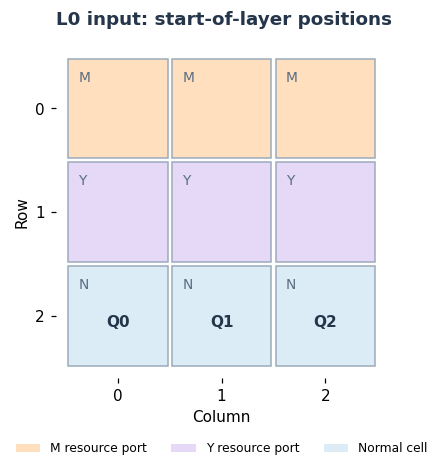

,layer,resource,interval_index,uop_id,uop_type,qregs,interval_type,begin_us,end_us,duration_us,layer_offset_us,global_begin_us,global_end_us
0,0,RMN_L,0,0,PATCH_H,"(Q0, Q1)",QOP,0.00,1.00,1.00,0.0,0.00,1.00
1,0,RMN_L,1,1,ESM,(),QOP,291.09,292.09,1.00,0.0,291.09,292.09
2,0,RMN_L,2,1,ESM,(),QOP,300.09,301.09,1.00,0.0,300.09,301.09
3,0,RMN_L,3,1,ESM,(),QOP,309.09,310.09,1.00,0.0,309.09,310.09
4,0,RMN_L,4,1,ESM,(),QOP,318.09,319.09,1.00,0.0,318.09,319.09
5,0,RMN_L,5,1,ESM,(),QOP,327.09,328.09,1.00,0.0,327.09,328.09
6,0,AODH_0,0,2,MOVE,"(M0,)",PICK,1.00,41.00,40.00,0.0,1.00,41.00
7,0,AODH_0,1,2,MOVE,"(M0,)",SHUTTLE,41.00,139.09,98.09,0.0,41.00,139.09
8,0,AODH_0,2,2,MOVE,"(M0,)",DROP,139.09,179.09,40.00,0.0,139.09,179.09
9,0,RYD_L,0,3,PATCH_CX,"(M0, Y1)",QOP,179.09,191.09,12.00,0.0,179.09,191.09


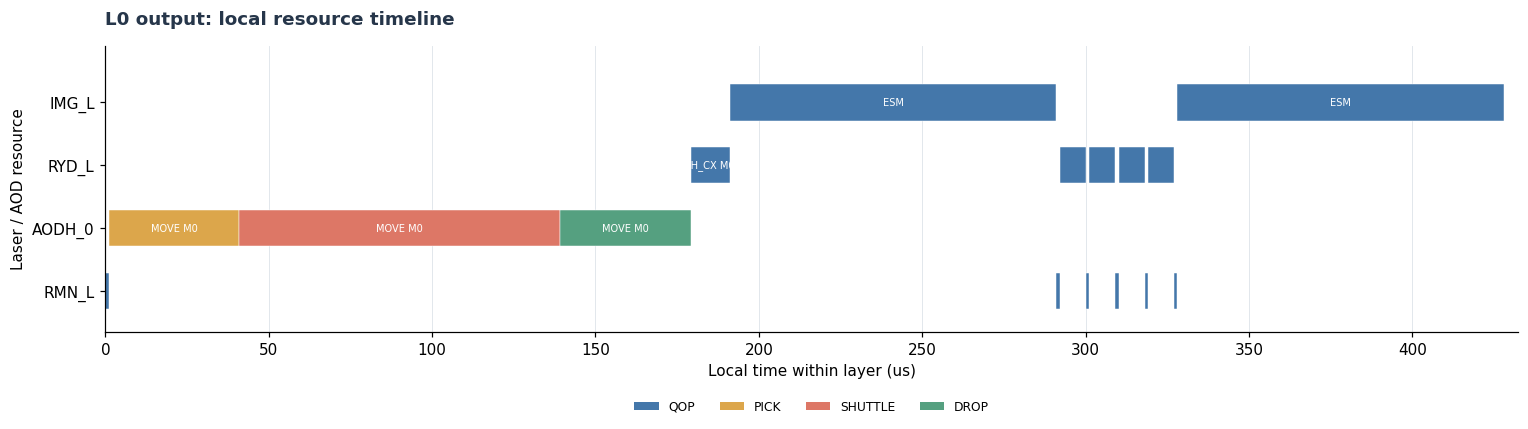

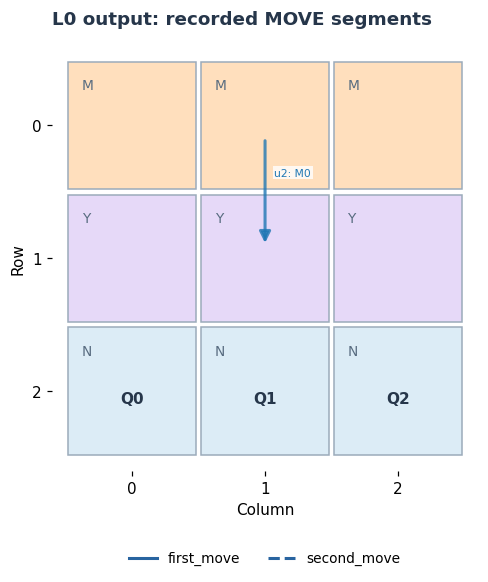

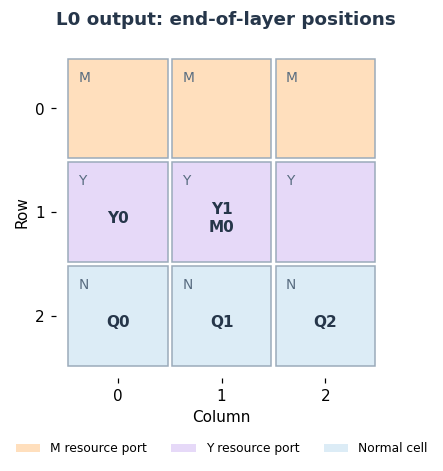

,layer,qreg,row,col,status
0,0,Q0,2,0,ACTIVE_B
1,0,Q1,2,1,ACTIVE_B
2,0,Q2,2,2,ACTIVE_A
3,0,Y1,1,1,ACTIVE_A
4,0,M0,1,1,ACTIVE_A
5,0,Y0,1,0,ACTIVE_A


In [9]:
def inspect_layer(layer):
    if not 0 <= layer < len(inst_schedule_trace):
        raise ValueError(f"layer 应在 0..{len(inst_schedule_trace)-1} 之间")
    start_plane = initial_plane if layer == 0 else plane_trace[layer - 1]
    start_qregs = initial_qregs if layer == 0 else qregs_trace[layer - 1]
    display(Markdown(f"### Layer {layer}: input / output"))
    display(instruction_df[instruction_df.layer == layer])
    show_figure(viz.draw_plane(start_plane, qregs=start_qregs, title=f"L{layer} input: start-of-layer positions"))
    display(uop_df[uop_df.layer == layer])
    show_figure(viz.draw_uop_gantt(uop_schedule_trace, layer=layer, title=f"L{layer} output: local resource timeline"))
    show_figure(viz.draw_move_paths(start_plane, uop_schedule_trace, layer=layer, qregs=start_qregs,
                                    title=f"L{layer} output: recorded MOVE segments"))
    show_figure(viz.draw_plane(plane_trace[layer], qregs=qregs_trace[layer], title=f"L{layer} output: end-of-layer positions"))
    display(qregs_df[qregs_df.layer == layer])

layers_with_moves = sorted(move_df.layer.unique().tolist()) if not move_df.empty else []
demo_layer = layers_with_moves[0] if layers_with_moves else 0
inspect_layer(demo_layer)


In [10]:
# 更改层号并重新运行此单元格，例如 inspect_layer(3)。
# 所有层的原始输入输出仍保留在 inst_schedule_trace/req_schedule_trace/
# uop_schedule_trace/plane_trace/qregs_trace 中。
print(f"Available layers: 0..{len(inst_schedule_trace)-1}; layers containing MOVE: {layers_with_moves}")
display(move_df)


Available layers: 0..8; layers containing MOVE: [0, 1, 2, 5, 7]


,layer,uop_id,phase,segment,qregs,direction,src_row,src_col,dst_row,dst_col,uop_begin_us,uop_end_us
0,0,2,first_move,0,"(M0,)",DOWN_Y,0,1,1,1,1.00,179.09
1,1,0,first_move,0,"(Q1,)",LEFT_X,2,1,2,0,0.00,178.09
2,2,0,first_move,0,"(Q1,)",RIGHT_X,2,0,2,1,0.00,178.09
3,2,5,first_move,0,"(Y0,)",DOWN_Y,1,0,2,0,343.78,658.05
4,2,6,first_move,0,"(M0,)",DOWN_Y,1,1,2,1,343.78,658.05
5,5,0,first_move,0,"(Q2,)",LEFT_X,2,2,2,1,0.00,178.09
6,7,0,first_move,0,"(Q2,)",LEFT_X,2,1,2,0,0.00,178.09


## 完整性检查与可导出的结果

以下断言验证展示的边界：输入 DAG 保留、指令与请求层对齐、映射落在 N 单元、
执行 trace 与逻辑层对齐、µop 时间区间非负，以及示例确实覆盖 H/CX/ROT、资源请求和 MOVE/ESM。
这些检查针对 demo 数据和图表解释，不代替 NAQsim 的完整物理/逻辑正确性验证。

全表导出为同目录 `demo_outputs/*.csv`，并写入配置、包版本和源码 SHA-256 记录。
notebook 本身保留执行输出，可在不重新运行 SA 的情况下阅读。


In [11]:
assert inst_dag.num_nodes() == len(dag_nodes)
assert len(inst_schedule_trace) == len(req_schedule_trace) == len(uop_schedule_trace)
assert len(plane_trace) == len(qregs_trace) == len(inst_schedule_trace)
assert set(qmap_init) == {f"Q{i}" for i in range(qc.num_qubits)}
assert all(plane_char[r][c] == "N" for r, c in qmap_init.values())
assert (uop_df.end_us >= uop_df.begin_us).all() and (uop_df.begin_us >= 0).all()
inst_types = {inst.inst_type for layer in inst_schedule_trace for inst in layer}
req_types = {inst.inst_type for layer in req_schedule_trace for inst in layer}
assert {InstType.TRANS_H, InstType.TRANS_CX, InstType.ROTATION} <= inst_types
assert InstType.REQ_MY in req_types or InstType.REQ_M in req_types
assert InstType.REQ_Y in req_types
assert any(uop.uop_type == UopType.MOVE for layer in uop_schedule_trace for intervals in layer.values()
           for uop, _, _ in intervals)
assert all(any(uop.uop_type == UopType.ESM for intervals in layer.values() for uop, _, _ in intervals)
           for layer in uop_schedule_trace)
assert rx.is_directed_acyclic_graph(inst_dag)
display(pd.DataFrame([{"pass": name, "wall_time_s": seconds} for name, seconds in timings.items()]))
print(f"Checks passed. Modeled total time: {duration_df.duration_us.sum():.3f} us.")


,pass,wall_time_s
0,1 translator,0.001272
1,2 plane initializer,0.000124
2,3 instruction scheduler,0.001548
3,4 SA mapper,0.694566
4,5 uop scheduler,0.035944


Checks passed. Modeled total time: 4146.280 us.


In [12]:
OUTPUT_DIR = NOTEBOOK_DIR / "demo_outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
tables = {"circuit": viz.circuit_table(qc), "dag_nodes": dag_nodes, "dag_edges": dag_edges,
          "instruction_layers": instruction_df, "uop_intervals": uop_df,
          "layer_durations": duration_df, "qreg_snapshots": qregs_df, "move_segments": move_df,
          "initial_mapping": pd.DataFrame([{"register": name, "row": pos[0], "column": pos[1]}
                                           for name, pos in qmap_init.items()]), "config": config_df}
for name, frame in tables.items():
    frame.to_csv(OUTPUT_DIR / f"{name}.csv", index=False, encoding="utf-8-sig")
source_files = ["config.py", "macro.py", "misc.py", "plane_initializer.py", "qreg_plane.py",
                "tsc_instructions.py", "latency_functions.py", "tsc_inst_translator.py",
                "tsc_inst_scheduler.py", "tsc_qubit_mapper_jit.py", "tsc_uop_scheduler_comptime.py",
                "case_study_hwcfg.json"]
revision = subprocess.run(["git", "-C", str(NAQSIM_ROOT), "rev-parse", "HEAD"],
                          capture_output=True, text=True, check=False).stdout.strip()
manifest = {"python": sys.version.split()[0], "interpreter": sys.executable,
            "kernel_name": "py311", "upstream_commit": revision,
            "packages": {name: version(name) for name in
                         ["qiskit", "numpy", "pandas", "scipy", "rustworkx", "matplotlib", "ipykernel"]},
            "source_sha256": {name: sha256((TSC_DIR / name).read_bytes()).hexdigest() for name in source_files},
            "sa_seed": 0, "sa_defaults": True, "num_logical_qubits": qc.num_qubits,
            "num_layers": len(inst_schedule_trace), "modeled_total_us": float(duration_df.duration_us.sum()),
            "wall_time_s": timings, "config": dict(zip(config_df.parameter, config_df.value)),
            "hardware_config": cfg.hw_cfg}
(OUTPUT_DIR / "manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Exported {len(tables)} tables and manifest to {OUTPUT_DIR}")


Exported 10 tables and manifest to D:\work\naqc\FT compiler\external\naqsim\notebooks\demo_outputs


## 阅读结果时的边界

- Q/M/Y 是逻辑寄存器名，S/T 传送后需结合 `translator.qubit_tracking` 解释身份变化。
- reset 翻译为 `INIT_Z`；执行模型从预初始化的 `ACTIVE_A` 码块开始，没有独立的初始化 µop。
- 条件 Pauli 留在编译 trace 的静态元数据；该时延模型未输出独立 Pauli 校正 µop，也不抽样条件结果。
- 同一 patch 可以容纳重叠的多个码块；空间图保留全部 occupants。
- SA 的距离代理成本、µop makespan、旋转数量是不同指标。
- `d=3` 和硬件参数用于教学示例，时间是模型输出，wall time 是本机 Python 运行耗时。
- 本 demo 没有调用拟合逻辑错误率模型，也没有进行量子态、含噪解码或资源态蒸馏仿真。
- 执行层内部步骤属于同一个上游模块；没有将其声明但未填充的 `uop_dag_trace` 当作实际输出。

源码对应入口：[`run_analysis_scripts.py`](../src/tsc_naa_sim/run_analysis_scripts.py)，
各 pass 的具体实现位于同目录。可调整输入线路后重新运行全部单元格；最后的覆盖断言专为本示例设计。
